In [8]:
import heapq

# TSP Branch and Bound

## Edges List

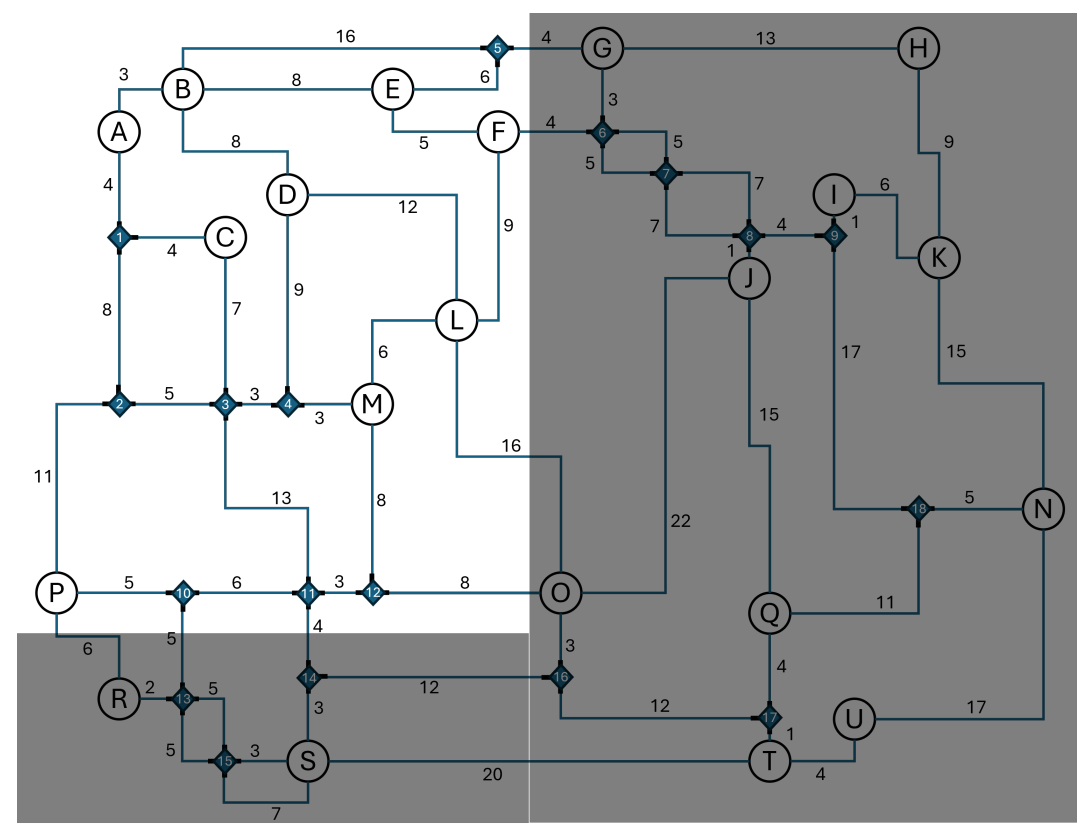

In [9]:
edges = [
    ('A', 'B', 3),
    ('A', 'C', 5),
    ('A', 'D', 2),
    ('A', 'E', 7),
    ('B', 'C', 8),
    ('B', 'D', 4),
    ('B', 'E', 2),
    ('C', 'D', 3),
    ('C', 'E', 4),
    ('D', 'E', 6),
]

## Adjacent List

In [10]:
def create_adjacentlist (edges):
    adj = {}
    for u, v, w in edges:
        if u not in adj:
            adj[u] = {}
        if v not in adj:
            adj[v] = {}

        if v not in adj[u]:
            adj[u][v] = w
            adj[v][u] = w
        else:
            adj[u][v] = min (adj[u][v], w)
            adj[v][u] = min (adj[u][v], w)

    return adj

## Initialisation

In [11]:
def initialize (edges):
    nodes = set()
    for u, v, _ in edges:
        nodes.add(u)
        nodes.add(v)
    nodes = list(nodes)
    return nodes

## Calculate Lowerbound

In [12]:
def calculate_lowerbound (edges, chosen_path):
    adj = create_adjacentlist(edges)
    nodes = initialize(edges)

    sum = 0
    k = len(chosen_path)

    for node in nodes:
        summand = 0

        if node in chosen_path:
            idx = chosen_path.index(node)

            if 0 < idx < k-1:
                pred_node = chosen_path[idx-1]
                suc_node = chosen_path[idx+1]
                summand = adj[node][pred_node] + adj[node][suc_node]

            elif idx == 0:
                if k>1:
                    suc_node = chosen_path[1]
                    fixed_weight = adj[node][suc_node]
                    rem_neighbours = {n: adj[node][n] for n in adj[node] if n!= suc_node}
                    min_edge = sorted(rem_neighbours.items(), key=lambda x: x[1])
                    summand= fixed_weight + min_edge[0][1]
                else:
                    two_min_edges = sorted(adj[node].items(), key=lambda x: x[1]) [:2]
                    summand = two_min_edges[0][1] + two_min_edges[1][1]

            elif idx == k-1:
                pred_node = chosen_path[idx-1]
                fixed_weight = adj[node][pred_node]
                rem_neighbours = {n: adj[node][n] for n in adj[node] if n!= pred_node}
                min_edge = sorted(rem_neighbours.items(), key=lambda x: x[1])
                summand= fixed_weight + min_edge[0][1]

        else:
            neighbours = adj[node]
            two_min_edges = sorted(neighbours.items(), key=lambda x: x[1]) [:2]
            first_node, weight1 = two_min_edges[0]
            second_node, weight2 = two_min_edges[1]
            summand = summand + weight1 + weight2

        sum += summand

    lb = sum / 2

    return lb

## Branch and Bound

In [13]:
def branch_and_bound (edges, start):
    min_dist = float('inf')
    best_tour = None

    nodes = initialize(edges)
    adj = create_adjacentlist(edges)

    heap = [] # (lb, current_path, rest_nodes)
    lb_start = calculate_lowerbound(edges, [start])
    initial_rest_nodes = [node for node in nodes if node != start]
    heapq.heappush(heap, (lb_start, [start], initial_rest_nodes))

    while heap:
        lb_curr, chosen_path, rest_nodes = heapq.heappop(heap)

        if lb_curr >= min_dist:
            continue

        start_node = chosen_path[-1]

        if not rest_nodes: # if there is no node which is not yet visited left
            if start in adj[start_node]:
                total_cost = lb_curr
                if total_cost < min_dist:
                    min_dist = total_cost
                    best_tour = chosen_path + [start]
            continue

        for neighbour, w in adj[start_node].items():
            if neighbour in rest_nodes:
                current_path = chosen_path + [neighbour]
                lb = calculate_lowerbound(edges, current_path)

                if lb >= min_dist:
                    continue
                else:
                    next_rest_nodes = [node for node in rest_nodes if node != neighbour]
                    heapq.heappush(heap, (lb, current_path, next_rest_nodes))
    return best_tour, min_dist

## Test Run

In [14]:
# --- Test Run ---
if __name__ == "__main__":
    start_node = 'A'
    best_tour, min_dist = branch_and_bound(edges, start=start_node)

    print("=" * 45)
    print("       TSP BRANCH AND BOUND - RESULT")
    print("=" * 45)
    print(f"Starting Node : {start_node}")
    print(f"Optimal Tour  : {' -> '.join(best_tour)}")
    print(f"Total Distance: {min_dist}")

       TSP BRANCH AND BOUND - RESULT
Starting Node : A
Optimal Tour  : A -> B -> E -> C -> D -> A
Total Distance: 14.0
